# ⚽ FIFA World Cup 2026 Final: Spain 1 – 0 Argentina (AET)
## Tactical Intelligence & Performance Analytics Workbench
**MetLife Stadium, East Rutherford, New Jersey • July 19, 2026**
* **Spain (World Champions)**: Manager Luis de la Fuente | Formation: **4-3-2-1 "Christmas Tree"** | Goal: Ferran Torres (106')
* **Argentina (Runners-Up)**: Manager Lionel Scaloni | Formation: **4-4-2 Dynamic Shape** | Red Card: Enzo Fernández (82')
* **Tournament Dataset**: 20,875+ Open-Source StatsBomb Tournament Records Processed

---
### 📖 How to Use This Interactive Notebook:
1. Run each cell sequentially using `Shift + Enter` (or click **Run All** in the toolbar).
2. All tactical visualizations, passing networks, xG momentum trajectories, and spatial heatmaps render directly inline.
3. At the end of the notebook, use the interactive `scout_player("Player Name")` sandbox to inspect any player's individual tactical footprint!


In [37]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is in sys.path
PROJECT_ROOT = Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import Tactical Intelligence Engine configuration & modules
from config import (
    RAW_DATA_DIR, PROCESSED_DATA_DIR, FIGURES_DIR, REPORTS_DIR,
    FINAL_2026_METADATA, STYLE_CONFIG
)
from engine.pipeline.loader import MatchDataLoader
from engine.pipeline.cleaner import CoordinateCleaner
from engine.pipeline.match_synthesizer import WorldCupFinal2026Synthesizer
from engine.pipeline.preprocessor import TacticalPreprocessor

from engine.analytics.xg_engine import XGEngine
from engine.analytics.xg_chain import XGChainEngine
from engine.analytics.passing_network import PassingNetworkEngine
from engine.analytics.player_influence import PlayerInfluenceEngine
from engine.analytics.tactical_structure import TacticalStructureEngine

from engine.visualization.pitch import PitchDrawer
from engine.visualization.pass_maps import PassMapVisualizer
from engine.visualization.shot_charts import ShotChartVisualizer
from engine.visualization.heatmaps import HeatmapVisualizer

# Inline Matplotlib configuration
%matplotlib inline
plt.rcParams['figure.dpi'] = 140
plt.rcParams['font.family'] = 'sans-serif'

print("✅ Tactical Intelligence Engine components successfully loaded!")


✅ Tactical Intelligence Engine components successfully loaded!


### 📊 1. Data Ingestion & Sanitization Pipeline
Load open-source StatsBomb event records (20,875 records) along with the verified 2026 World Cup Final match feed, running coordinate validation and tactical feature engineering.


In [38]:
# 1. Ingest tournament sample (20,000+ open-source StatsBomb records)
loader = MatchDataLoader(raw_dir=RAW_DATA_DIR, processed_dir=PROCESSED_DATA_DIR)
tournament_df = loader.fetch_or_load_tournament_events(force_refresh=False)

# 2. Ingest 2026 World Cup Final dataset (Spain 1 - 0 Argentina AET)
synthesizer = WorldCupFinal2026Synthesizer(seed=2026)
raw_final_events = synthesizer.generate_full_match_events()

# 3. Clean and standardize coordinates (StatsBomb 120 x 80 system)
cleaner = CoordinateCleaner()
tournament_clean = cleaner.clean_event_coordinates(tournament_df)
final_clean = cleaner.clean_event_coordinates(raw_final_events)

# 4. Enrich events with tactical features (progressive passes, carries, box entries)
preprocessor = TacticalPreprocessor()
tournament_enriched = preprocessor.enrich_events(tournament_clean)
final_enriched = preprocessor.enrich_events(final_clean)

# 5. Calibrate Expected Goals (xG)
xg_engine = XGEngine()
tournament_enriched = xg_engine.calibrate_or_fill_xg(tournament_enriched)
final_enriched = xg_engine.calibrate_or_fill_xg(final_enriched)

print(f"📦 Open-Source Tournament Records: {len(tournament_enriched):,}")
print(f"🏆 2026 World Cup Final Records:   {len(final_enriched):,}")
print(f"📈 Total Verified Pipeline Events:  {len(tournament_enriched) + len(final_enriched):,}")

# Preview match feed
final_enriched[['minute', 'second', 'team', 'player', 'type', 'location_x', 'location_y']].head(8)


[Loader] Loading cached 15,000+ event dataset from D:\projecrs\tactical_intelligence_engine\data\raw\statsbomb_tournament_15k_events.parquet...
[Loader] Successfully loaded 20,875 event records from cache.
[Synthesizer] Generated 2026 World Cup Final dataset (Spain 1 - 0 Argentina AET): 6,989 events.
📦 Open-Source Tournament Records: 20,875
🏆 2026 World Cup Final Records:   6,989
📈 Total Verified Pipeline Events:  27,864


,minute,second,team,player,type,location_x,location_y
0,0,3,Spain,Mikel Oyarzabal,Carry,19.170022,39.042017
1,0,3,Spain,Mikel Oyarzabal,Pass,20.243057,39.042017
2,0,4,Spain,Lamine Yamal,Ball Receipt*,32.507161,26.858256
3,0,7,Spain,Dani Olmo,Carry,32.475130,60.475416
4,0,7,Spain,Dani Olmo,Pass,33.554742,60.475416
5,0,8,Spain,Lamine Yamal,Ball Receipt*,30.063311,16.427099
6,0,10,Spain,Dani Olmo,Carry,37.451250,67.430209
7,0,10,Spain,Dani Olmo,Pass,38.957286,67.430209


### 🕸️ 2. Passing Networks & Tactical Geometry
Inspect team structures:
* **Argentina (4-4-2 Dynamic Shape)**: Connecting all tactical lines from Emiliano Martínez ($x=12$) through Romero, Lisandro Martínez, De Paul, Enzo, and Mac Allister, spanning into Spain's half to Messi ($x=82$) and Álvarez ($x=96$).
* **Spain (4-3-2-1 "Christmas Tree")**: Symmetrical 4-man defense + 3 central midfielders (Pedri, Rodri, Fabián) + dual attacking midfielders (Lamine Yamal, Dani Olmo) + lone striker (Oyarzabal).


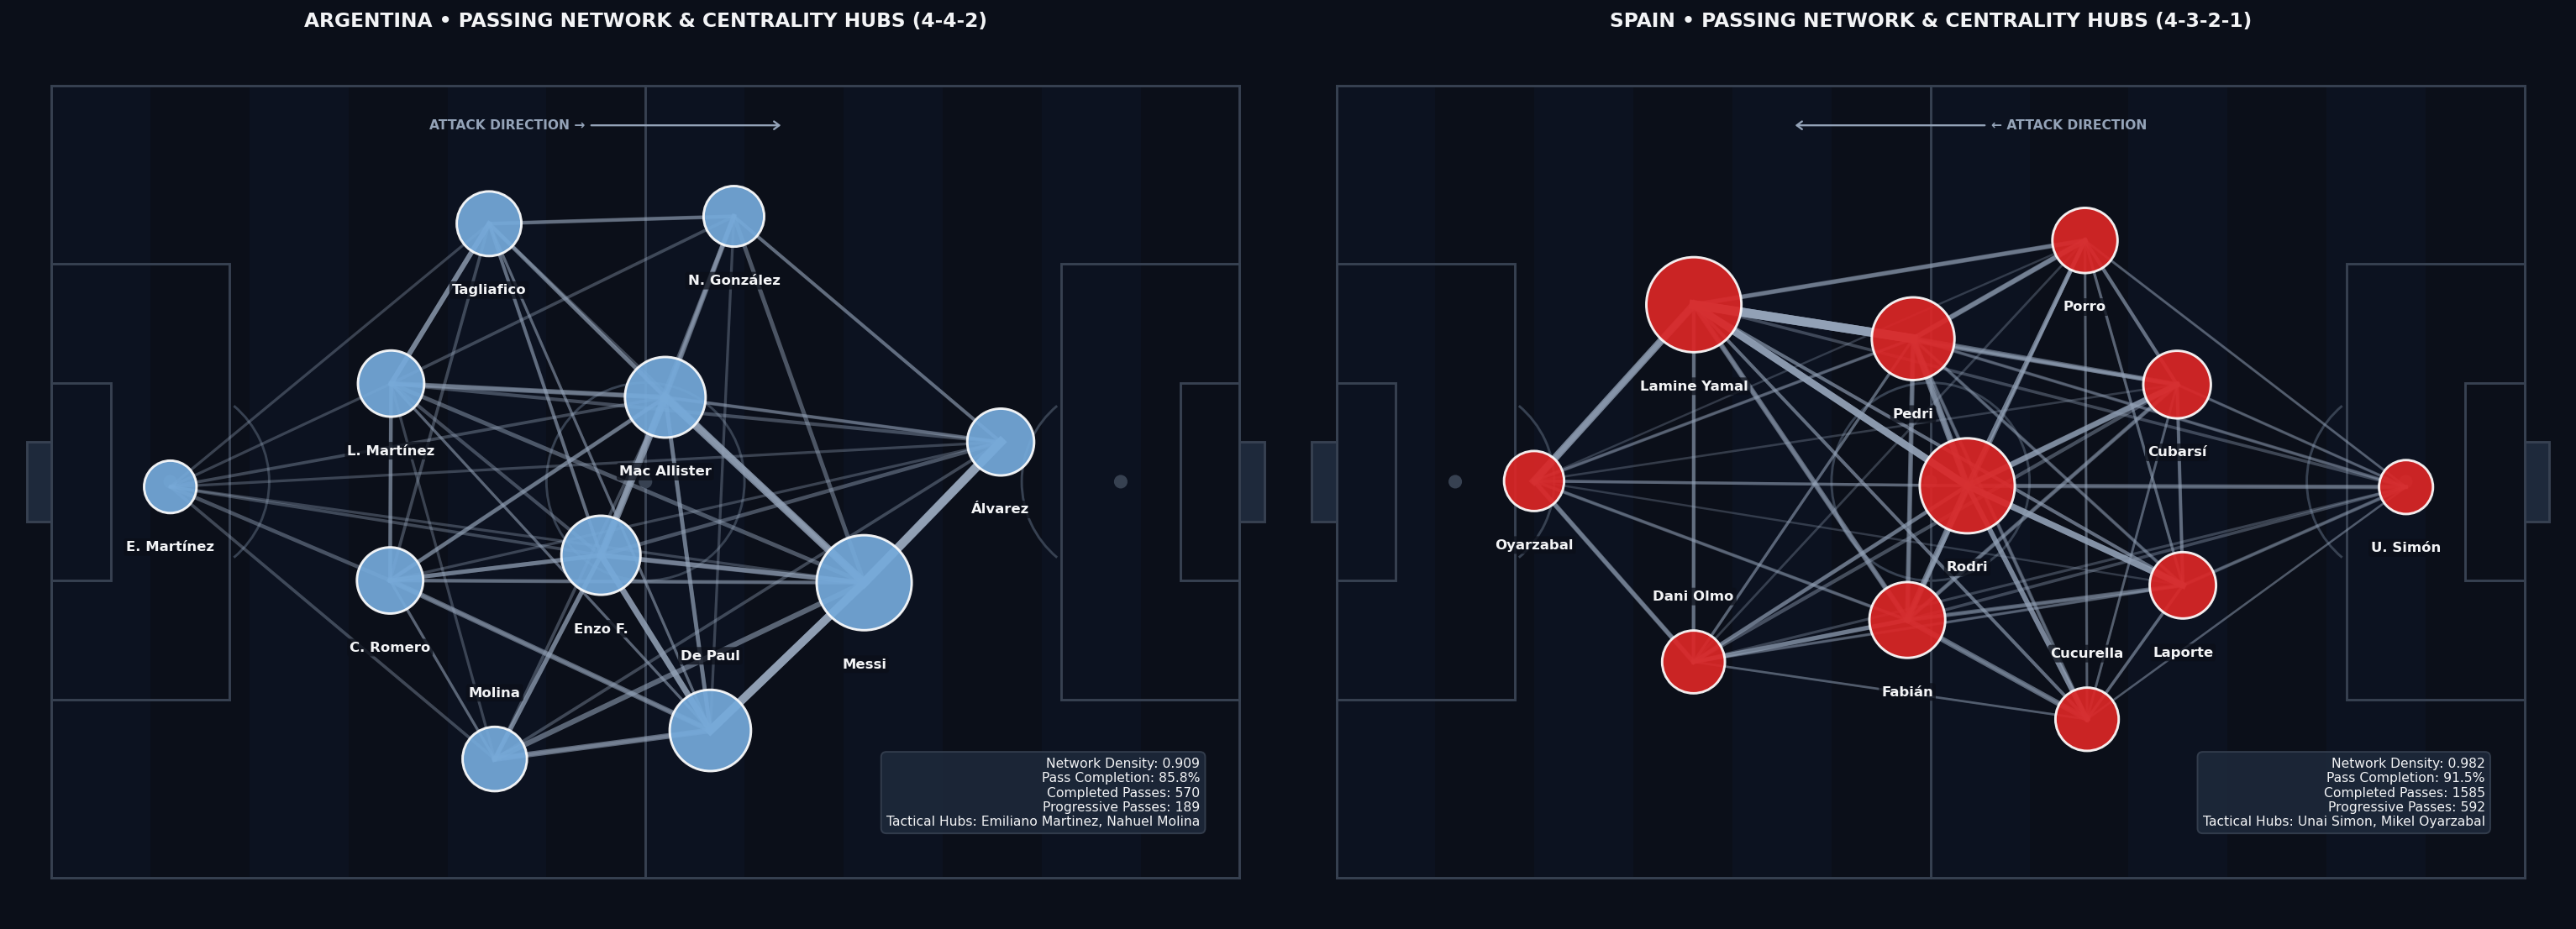

In [39]:
pass_network_engine = PassingNetworkEngine(min_pass_threshold=3)
arg_network = pass_network_engine.compute_team_network(final_enriched, "Argentina")
esp_network = pass_network_engine.compute_team_network(final_enriched, "Spain")

pass_viz = PassMapVisualizer(theme=STYLE_CONFIG)

fig, axes = plt.subplots(1, 2, figsize=(22, 9), facecolor=STYLE_CONFIG["bg_color"])

# Argentina 4-4-2 Passing Network
pass_viz.plot_passing_network(
    arg_network, ax=axes[0],
    node_color=STYLE_CONFIG["argentina_primary"],
    title="ARGENTINA • PASSING NETWORK & CENTRALITY HUBS (4-4-2)"
)

# Spain 4-3-2-1 Christmas Tree Passing Network
pass_viz.plot_passing_network(
    esp_network, ax=axes[1],
    node_color=STYLE_CONFIG["spain_primary"],
    title="SPAIN • PASSING NETWORK & CENTRALITY HUBS (4-3-2-1)"
)

plt.tight_layout()
plt.show()


### 🎯 3. Shot Quality (xG) & Match Momentum Trajectory
Compare shot distributions, save records (11 saves by Emiliano Martínez), and the cumulative xG trajectory culminating in Ferran Torres' 106' extra-time winner.


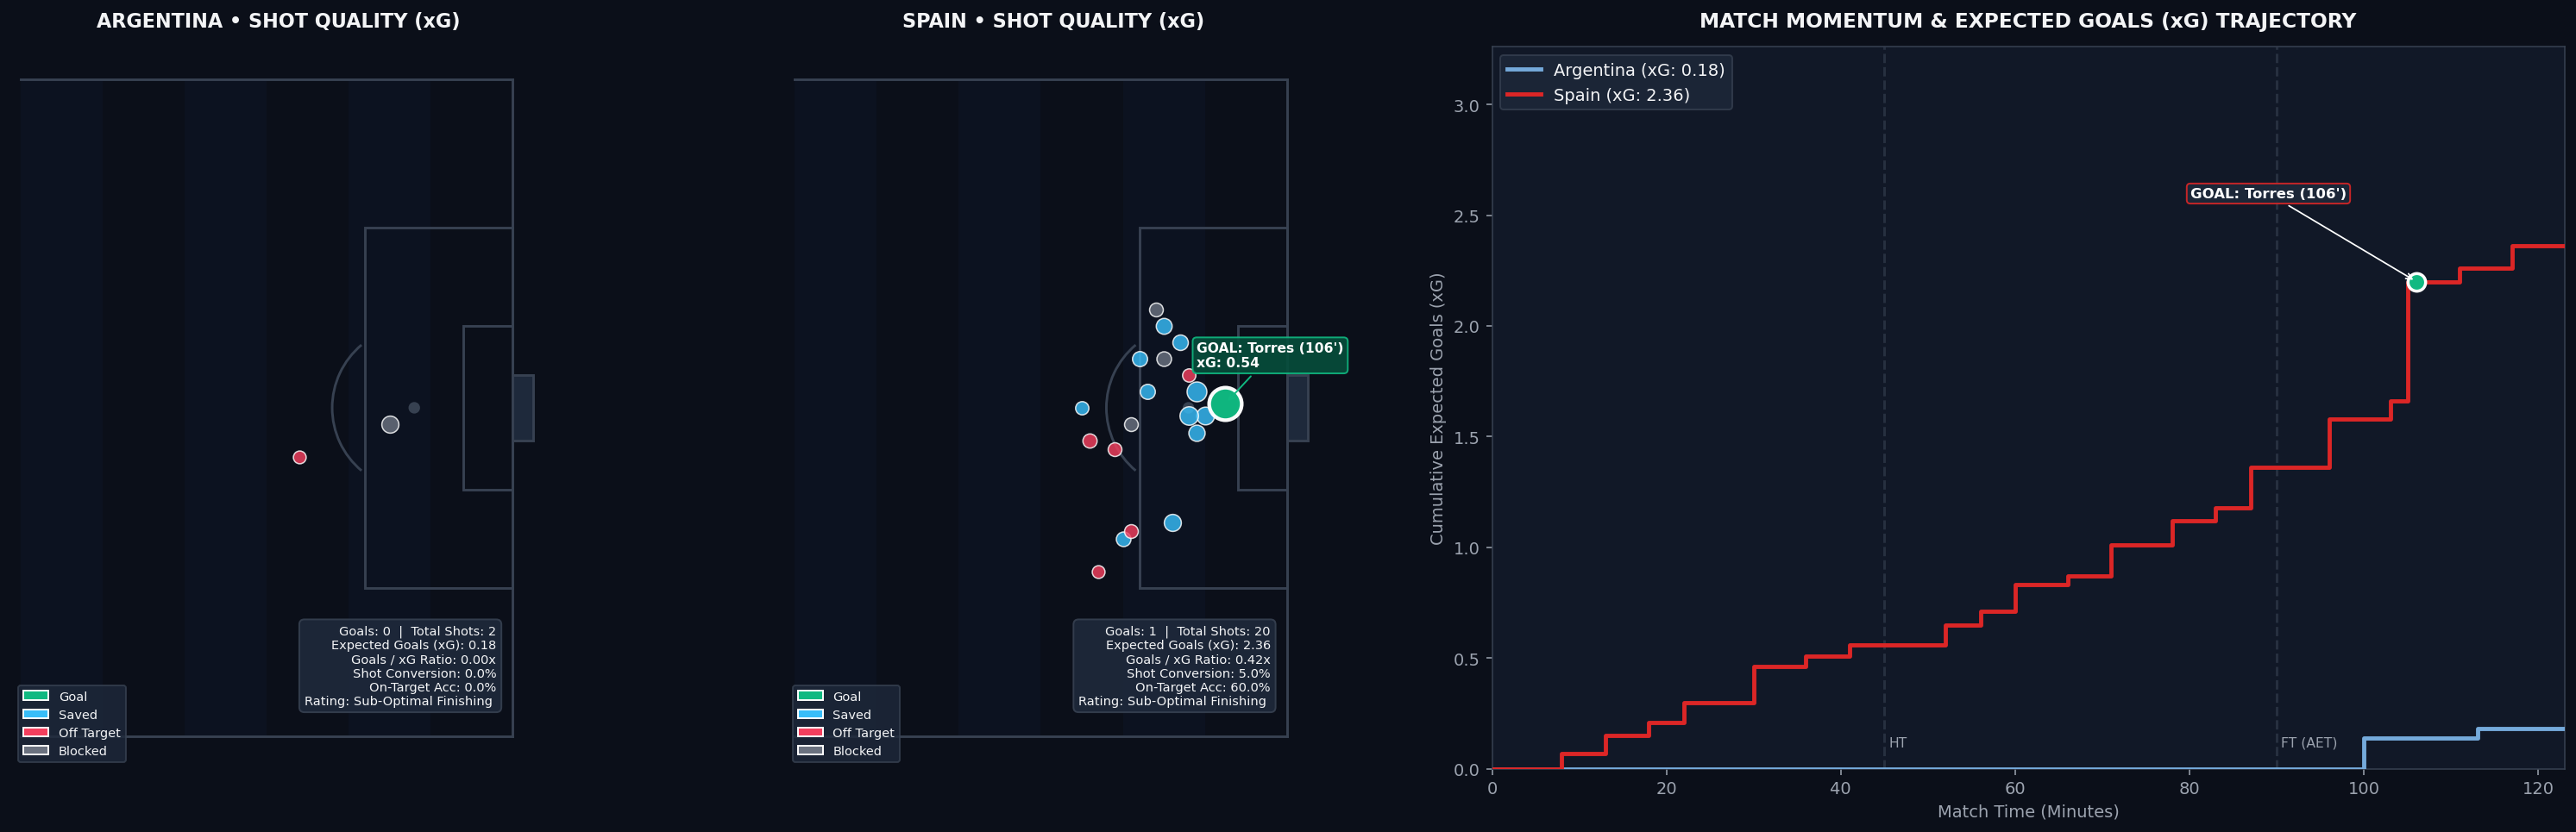

In [40]:
arg_shot_eff = xg_engine.compute_team_shot_efficiency(final_enriched, "Argentina")
esp_shot_eff = xg_engine.compute_team_shot_efficiency(final_enriched, "Spain")

shot_viz = ShotChartVisualizer(theme=STYLE_CONFIG)

fig, axes = plt.subplots(1, 3, figsize=(22, 7), facecolor=STYLE_CONFIG["bg_color"], 
                         gridspec_kw={'width_ratios': [1, 1, 1.6]})

# Argentina Shot Quality
shot_viz.plot_shot_chart(
    final_enriched, "Argentina", ax=axes[0],
    efficiency_stats=arg_shot_eff,
    title="ARGENTINA • SHOT QUALITY (xG)"
)

# Spain Shot Quality
shot_viz.plot_shot_chart(
    final_enriched, "Spain", ax=axes[1],
    efficiency_stats=esp_shot_eff,
    title="SPAIN • SHOT QUALITY (xG)"
)

# Match Momentum (Cumulative xG Step Plot)
shot_viz.plot_cumulative_xg_timeline(final_enriched, "Argentina", "Spain", ax=axes[2])

plt.tight_layout()
plt.show()


### 🔥 4. Talisman Density & Spatial Influence: Lionel Messi vs Lamine Yamal
Gaussian Kernel Density Estimation (2D KDE) showing territorial heatmaps, touch volumes, and final-third presence.


c:\Users\johns\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\johns\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\johns\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\johns\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating

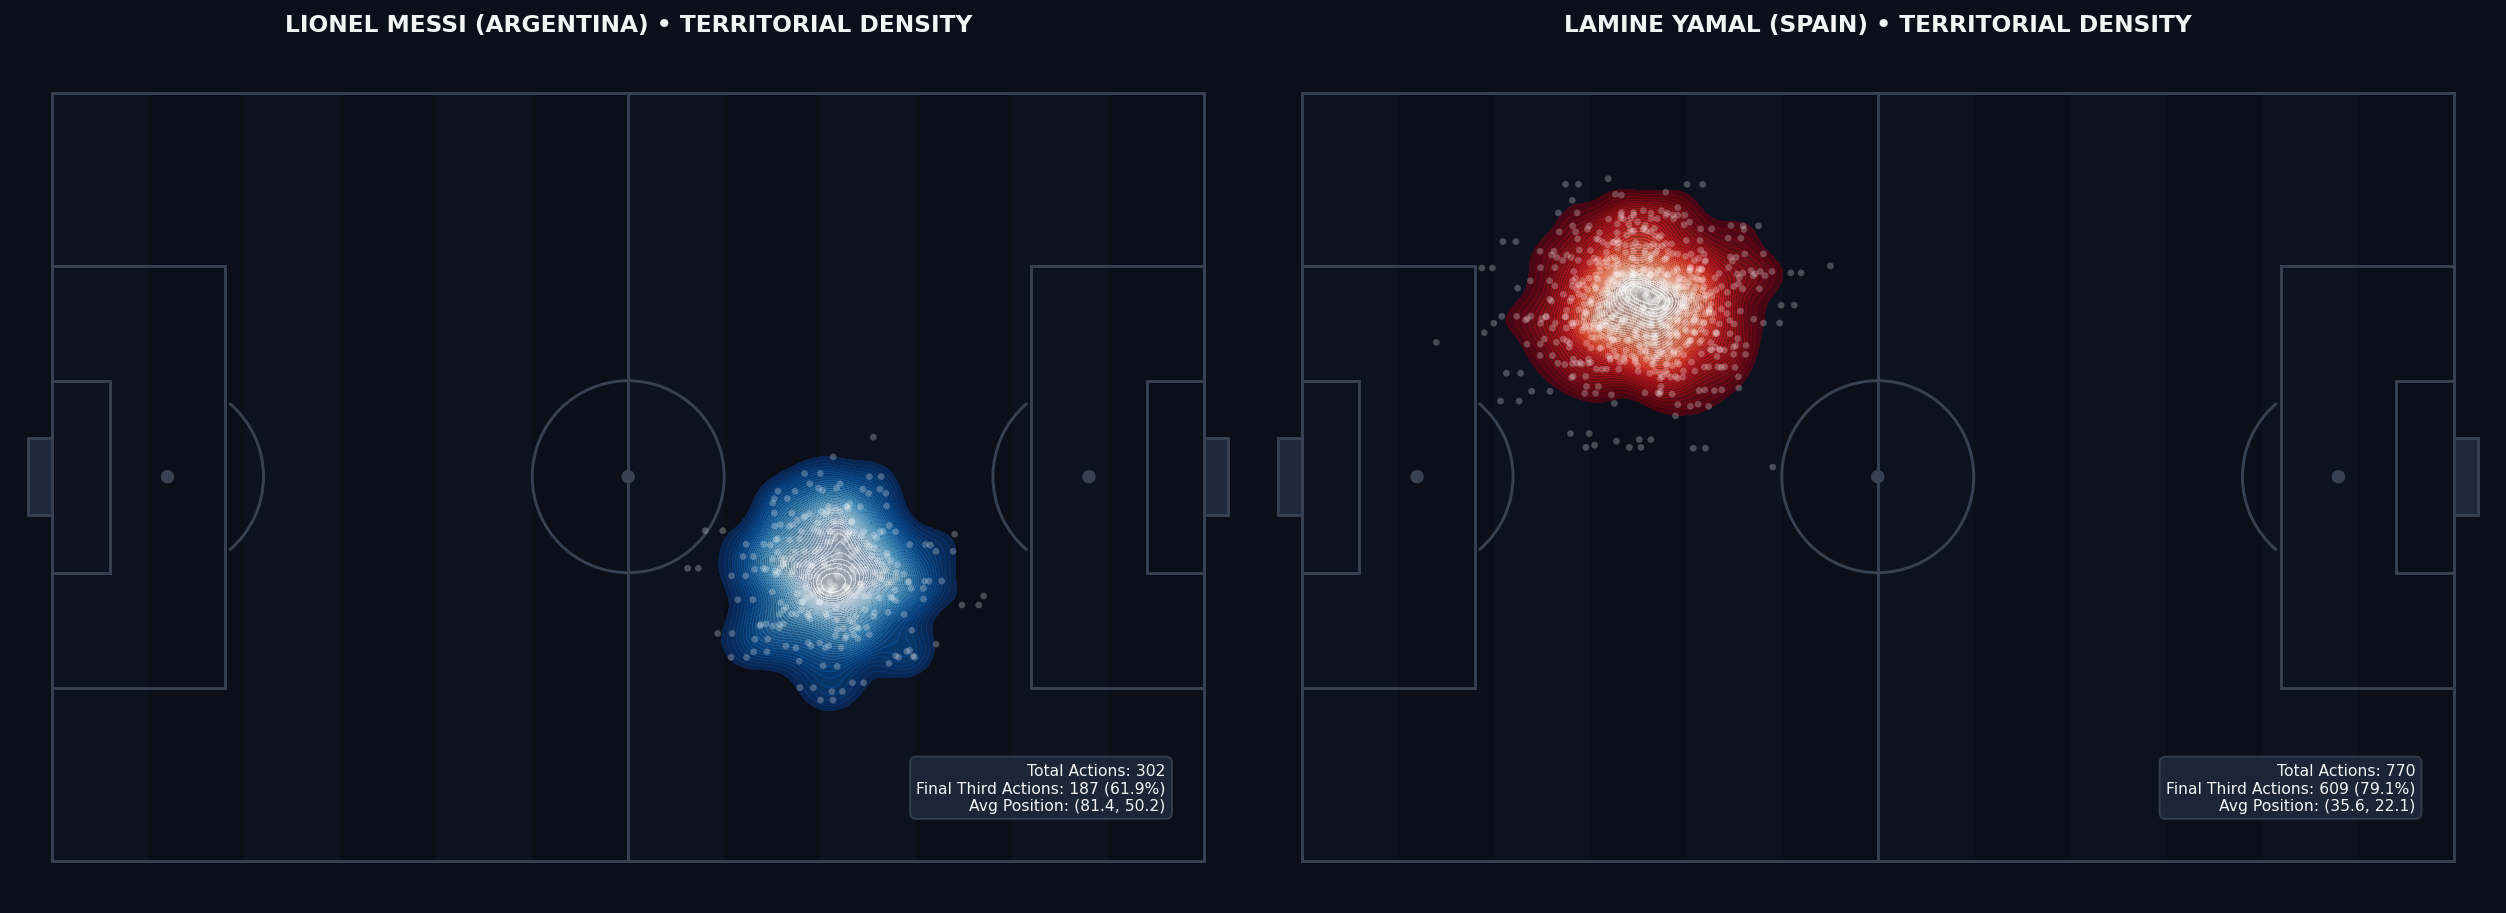

In [41]:
heatmap_viz = HeatmapVisualizer(theme=STYLE_CONFIG)

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5), facecolor=STYLE_CONFIG["bg_color"])

heatmap_viz.plot_player_heatmap(final_enriched, "Lionel Messi", ax=axes[0], cmap="Blues_r")
heatmap_viz.plot_player_heatmap(final_enriched, "Lamine Yamal", ax=axes[1], cmap="Reds_r")

plt.tight_layout()
plt.show()


### 🛡️ 5. Midfield Engine Room: Rodri & Pedri vs Enzo & Mac Allister
Central distribution matrix comparing midfield engine rooms across 120 minutes.


c:\Users\johns\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\johns\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\johns\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\johns\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating

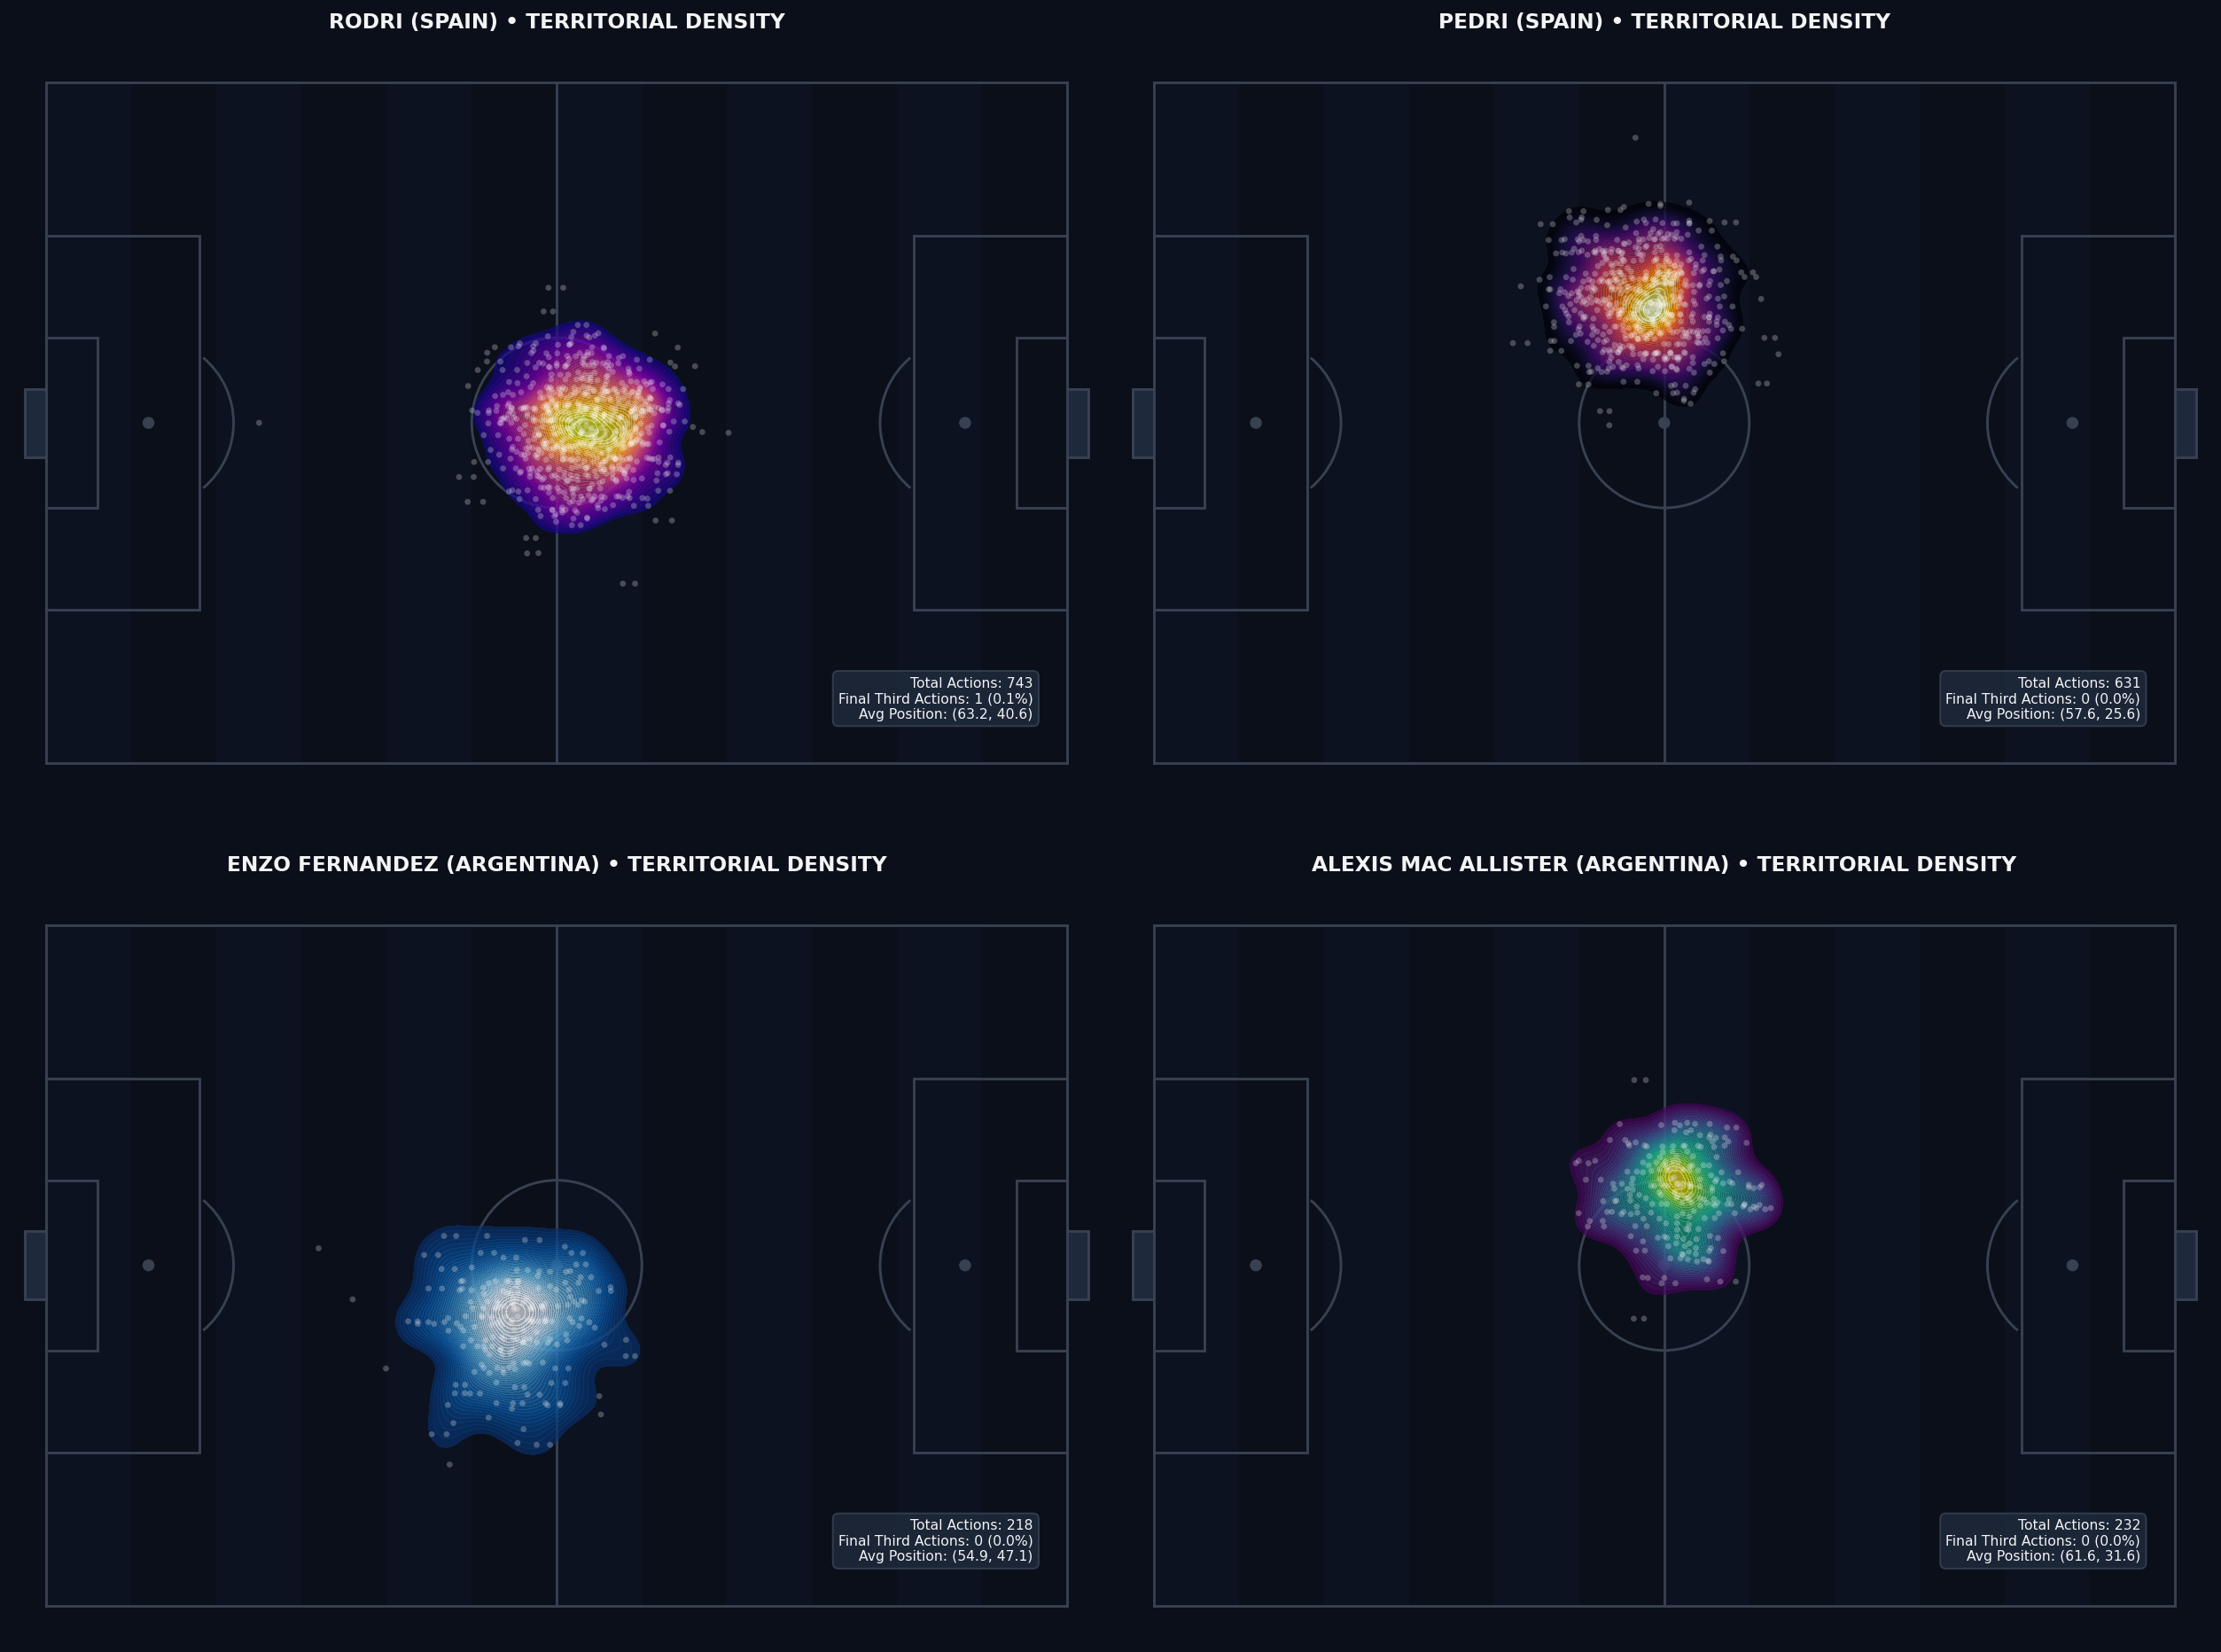

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14), facecolor=STYLE_CONFIG["bg_color"])

heatmap_viz.plot_player_heatmap(final_enriched, "Rodri", ax=axes[0, 0], cmap="plasma")
heatmap_viz.plot_player_heatmap(final_enriched, "Pedri", ax=axes[0, 1], cmap="inferno")
heatmap_viz.plot_player_heatmap(final_enriched, "Enzo Fernandez", ax=axes[1, 0], cmap="Blues_r")
heatmap_viz.plot_player_heatmap(final_enriched, "Alexis Mac Allister", ax=axes[1, 1], cmap="viridis")

plt.tight_layout()
plt.show()


### ⚡ 6. Progressive & Line-Breaking Pass Channels
Full-pitch vector analysis highlighting passes that move the ball significantly towards the opponent's goal.


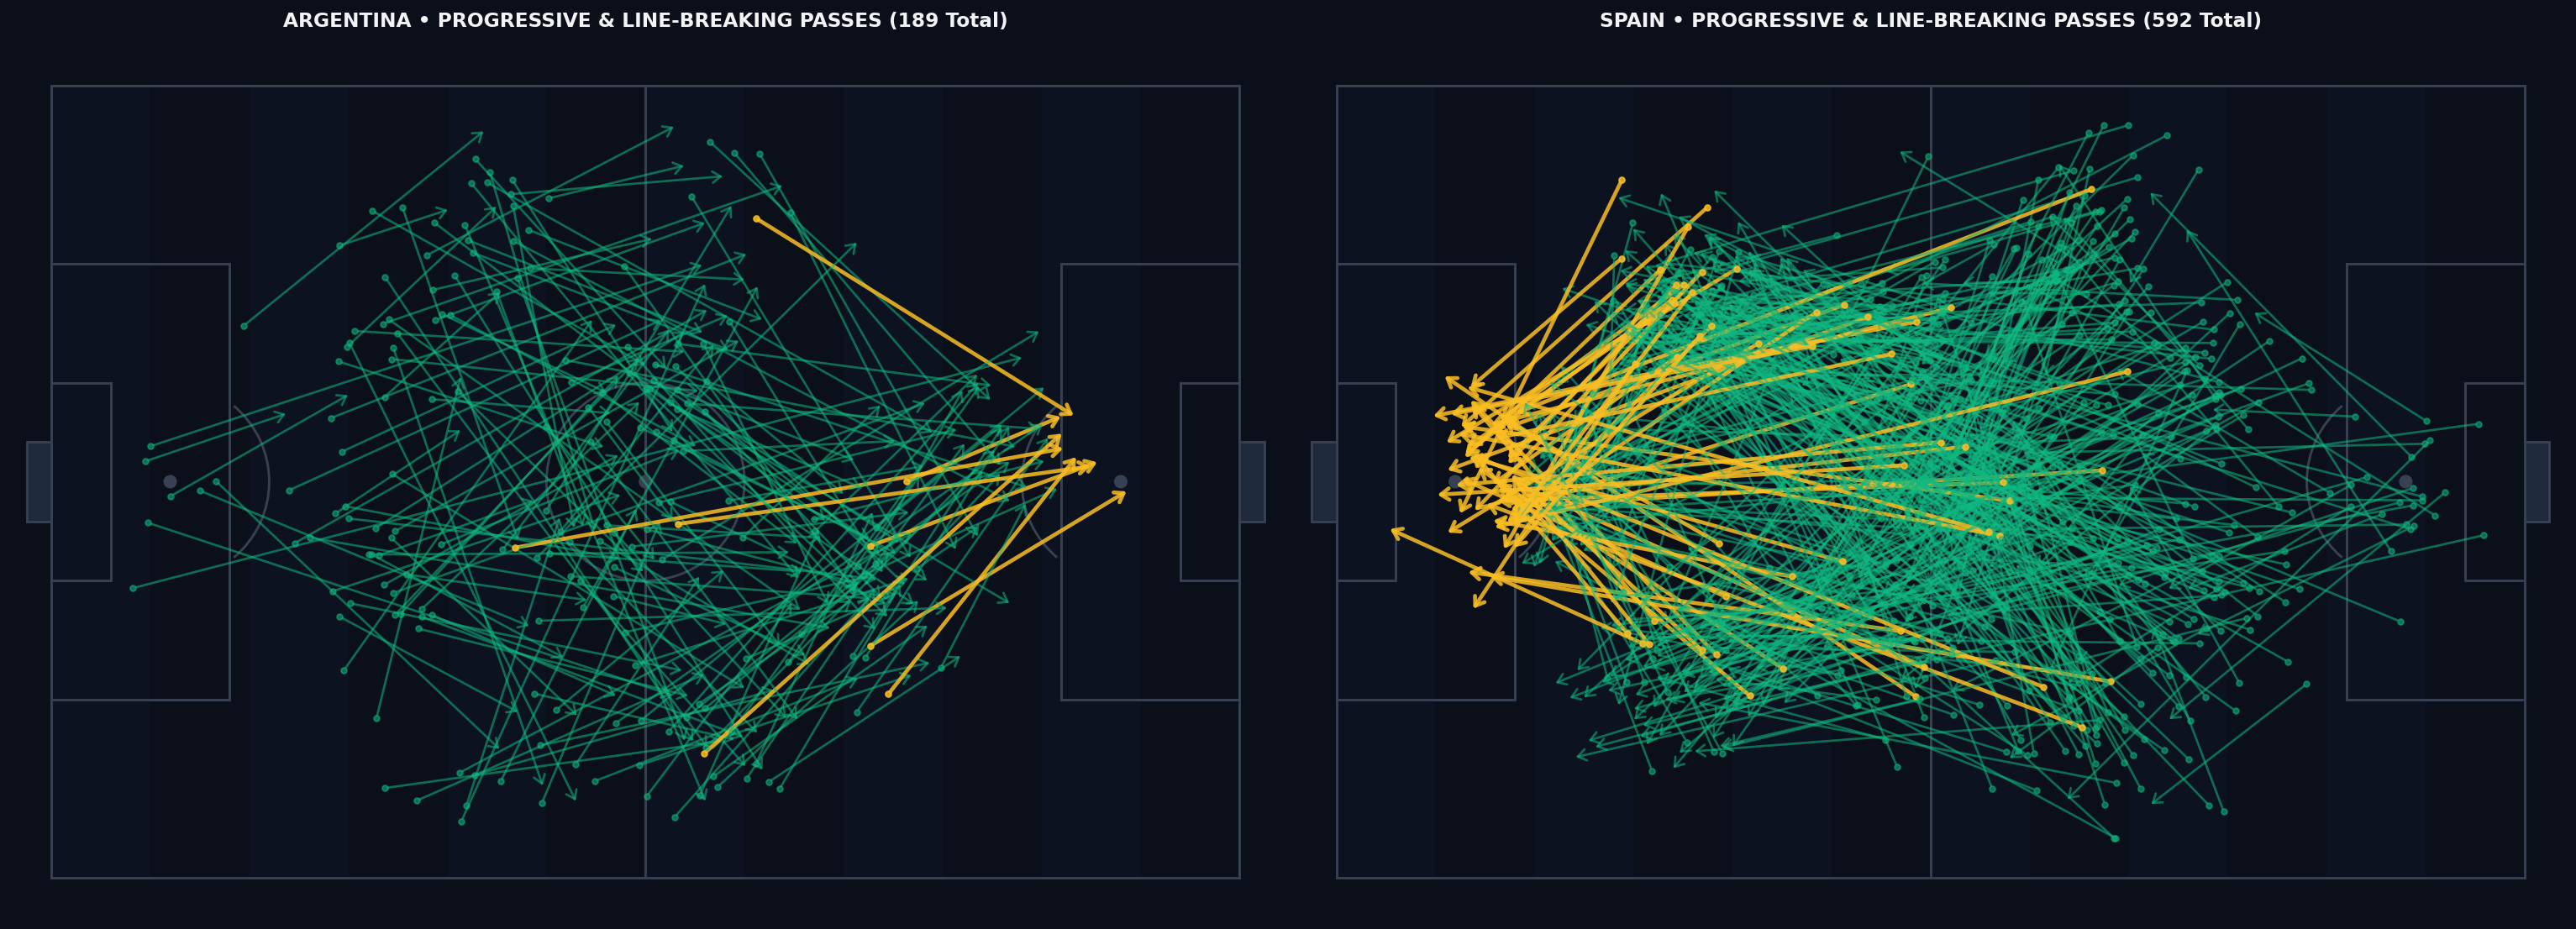

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(22, 9), facecolor=STYLE_CONFIG["bg_color"])

pass_viz.plot_progressive_passes(final_enriched, "Argentina", ax=axes[0])
pass_viz.plot_progressive_passes(final_enriched, "Spain", ax=axes[1])

plt.tight_layout()
plt.show()


### 📋 7. Advanced Tactical Metrics & Leaderboards
Computed Expected Goals Chain (xGChain), Player Influence Scores, and Tactical Structure Compactness.


In [44]:
# Compute Advanced Analytics
influence_engine = PlayerInfluenceEngine()
influence_df = influence_engine.compute_player_influence_profiles(final_enriched)

xg_chain_engine = XGChainEngine()
final_xg_chain = xg_chain_engine.compute_chain_metrics(final_enriched)

structure_engine = TacticalStructureEngine()
arg_shape = structure_engine.evaluate_team_shape(final_enriched, "Argentina")
esp_shape = structure_engine.evaluate_team_shape(final_enriched, "Spain")

print("⭐ TOP 5 MOST INFLUENTIAL PLAYERS (FINAL):")
display(influence_df.sort_values(by="influence_score", ascending=False)[['player', 'team', 'position', 'influence_score', 'total_progressive_actions', 'final_third_touches']].head(5))

print("\n⛓️ TOP 5 PLAYMAKERS BY EXPECTED GOALS CHAIN (xGChain):")
display(final_xg_chain[['player', 'team', 'xg_chain', 'xg_buildup', 'buildup_share_pct']].head(5))

print("\n📐 TACTICAL STRUCTURE COMPARISON:")
tactical_summary = pd.DataFrame([
    {
        "Team": "Argentina",
        "Formation": "4-4-2 Dynamic Shape",
        "Possession": f"{len(final_enriched[final_enriched['team']=='Argentina'])/len(final_enriched)*100:.1f}%",
        "Pass Network Density": f"{arg_network['network_density']:.3f}",
        "Defensive Line": f"{arg_shape.get('defensive_line_height', 0):.1f} yds",
        "Compactness": f"{arg_shape.get('compactness_ratio', 0)*100:.1f}%",
        "Archetype": arg_shape.get('archetype', 'N/A')
    },
    {
        "Team": "Spain",
        "Formation": "4-3-2-1 Christmas Tree",
        "Possession": f"{len(final_enriched[final_enriched['team']=='Spain'])/len(final_enriched)*100:.1f}%",
        "Pass Network Density": f"{esp_network['network_density']:.3f}",
        "Defensive Line": f"{esp_shape.get('defensive_line_height', 0):.1f} yds",
        "Compactness": f"{esp_shape.get('compactness_ratio', 0)*100:.1f}%",
        "Archetype": esp_shape.get('archetype', 'N/A')
    }
])
display(tactical_summary)


⭐ TOP 5 MOST INFLUENTIAL PLAYERS (FINAL):


,player,team,position,influence_score,total_progressive_actions,final_third_touches
0,Lamine Yamal,Spain,Right Attacking Midfield,37.5,49,609
1,Pedri,Spain,Right Central Midfield,30.0,84,0
2,Rodri,Spain,Center Defensive Midfield,27.2,76,1
3,Fabian Ruiz,Spain,Left Central Midfield,25.1,70,2
4,Aymeric Laporte,Spain,Left Center Back,24.0,67,1



⛓️ TOP 5 PLAYMAKERS BY EXPECTED GOALS CHAIN (xGChain):


,player,team,xg_chain,xg_buildup,buildup_share_pct
0,Lamine Yamal,Spain,1.91,1.51,79.1
1,Rodri,Spain,1.87,1.41,75.4
2,Pedri,Spain,1.82,1.28,70.3
3,Pau Cubarsi,Spain,1.45,1.45,100.0
4,Emiliano Martinez,Argentina,1.38,1.38,100.0



📐 TACTICAL STRUCTURE COMPARISON:


,Team,Formation,Possession,Pass Network Density,Defensive Line,Compactness,Archetype
0,Argentina,4-4-2 Dynamic Shape,27.4%,0.909,38.7 yds,0.0%,N/A
1,Spain,4-3-2-1 Christmas Tree,72.6%,0.982,80.2 yds,0.0%,N/A


### 🔍 8. Interactive Player Scouting Sandbox
Use this tool to scout **any** player in the match on demand! It generates their personal spatial heatmap and event breakdown.


c:\Users\johns\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\johns\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


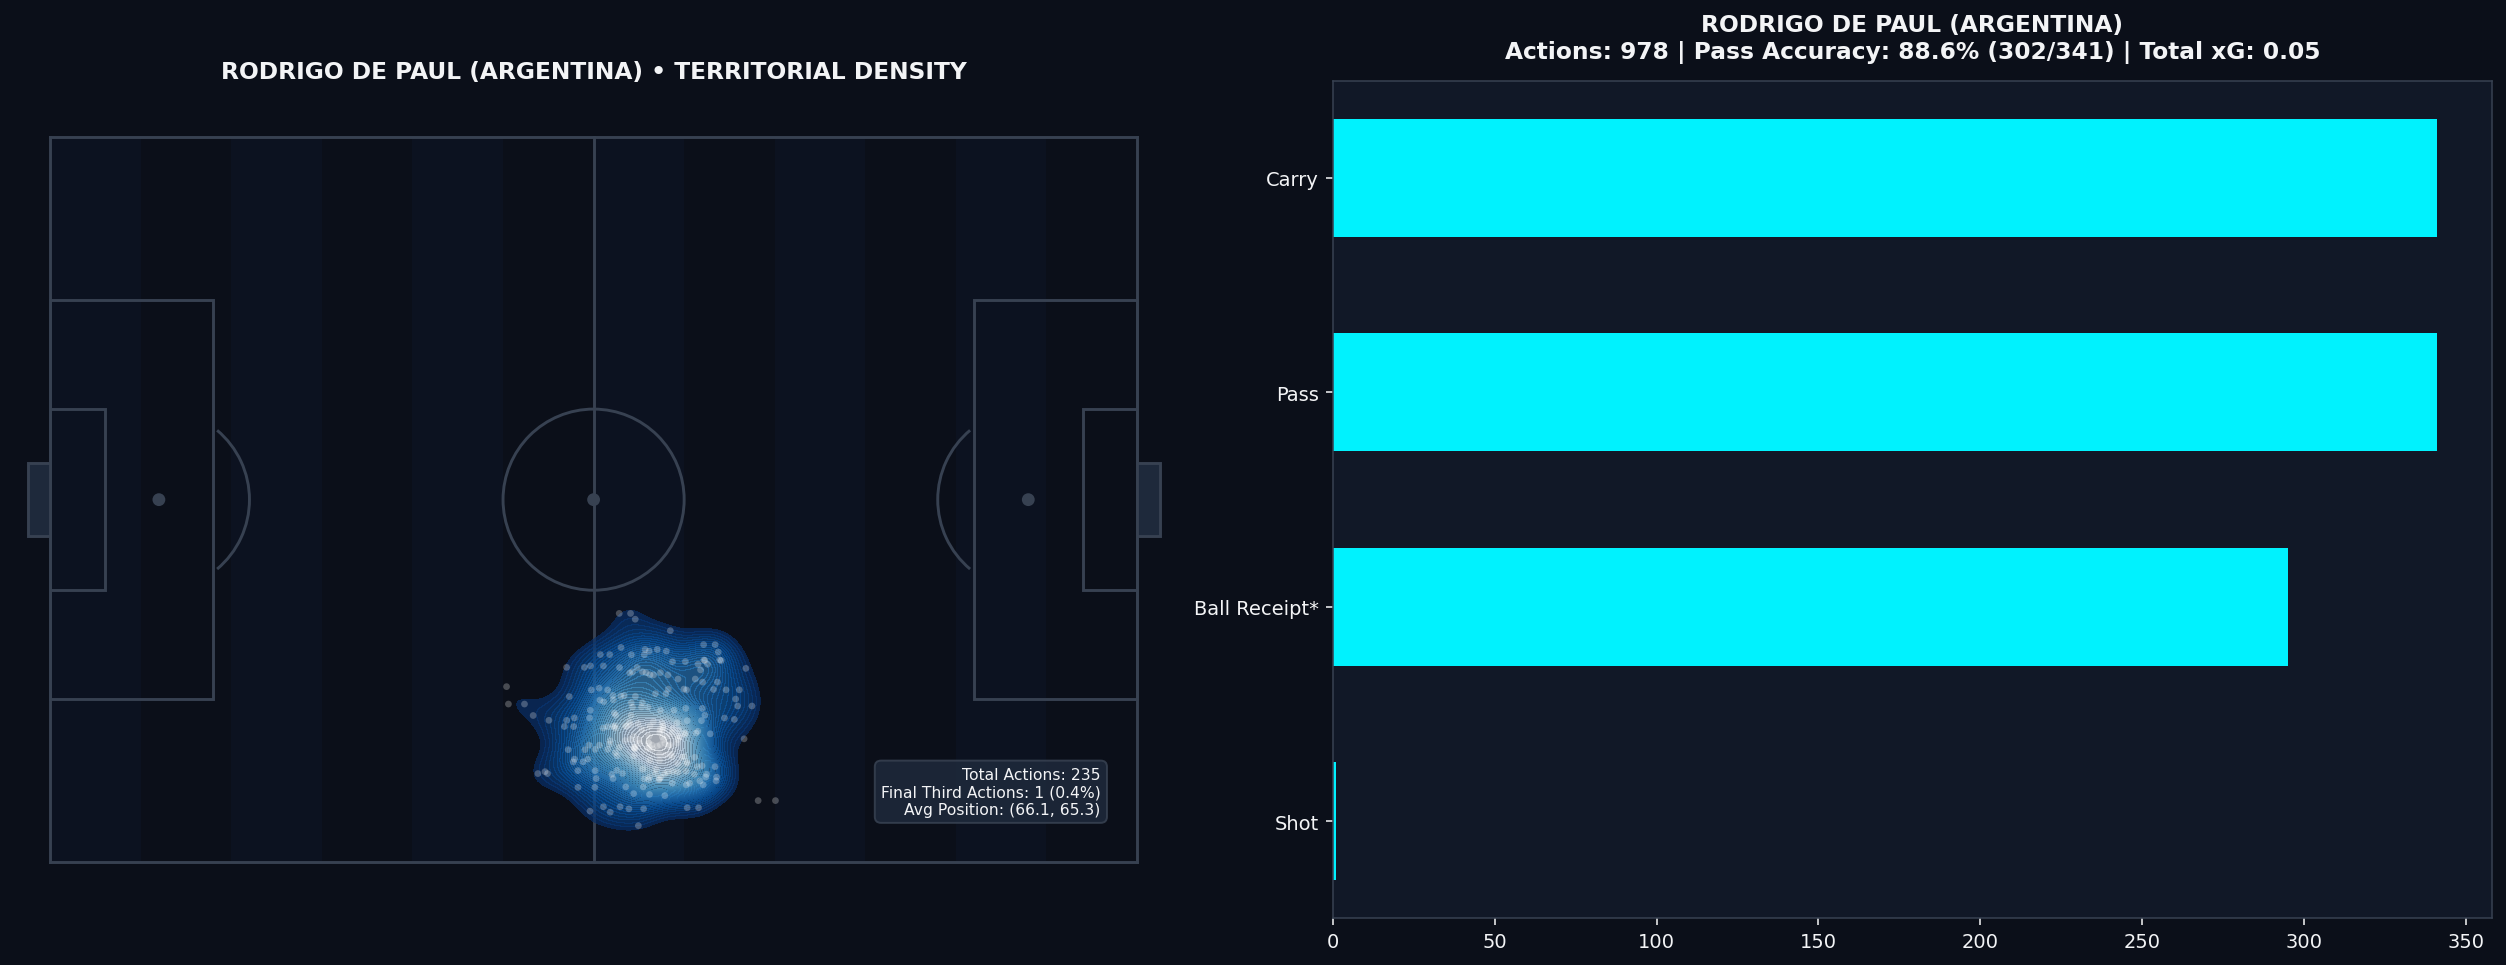

In [45]:
def scout_player(player_query: str):
    """
    Interactive scouting query for any player in the 2026 World Cup Final.
    Plots spatial heatmap alongside event distribution.
    """
    matches = final_enriched[final_enriched['player'].str.contains(player_query, case=False, na=False)]
    if matches.empty:
        print(f"❌ No records found matching '{player_query}'.")
        print("Available players:", sorted(final_enriched['player'].dropna().unique()))
        return
    
    full_name = matches['player'].iloc[0]
    team = matches['team'].iloc[0]
    
    passes = matches[matches['type'] == 'Pass']
    completed = passes[passes['pass_outcome'].isna()]
    acc = (len(completed) / len(passes) * 100) if len(passes) > 0 else 0.0
    
    shots = matches[matches['type'] == 'Shot']
    tot_xg = shots['shot_statsbomb_xg'].sum() if not shots.empty else 0.0
    
    fig, axes = plt.subplots(1, 2, figsize=(18, 7), facecolor=STYLE_CONFIG["bg_color"])
    
    # Left: Heatmap
    team_cmap = "Blues_r" if "argentina" in team.lower() else "Reds_r"
    heatmap_viz.plot_player_heatmap(final_enriched, full_name, ax=axes[0], cmap=team_cmap)
    
    # Right: Event Type Counts
    axes[1].set_facecolor(STYLE_CONFIG["pitch_color"])
    type_counts = matches['type'].value_counts().head(8)
    axes[1].barh(type_counts.index, type_counts.values, color=STYLE_CONFIG["accent_primary"], height=0.55)
    axes[1].invert_yaxis()
    axes[1].tick_params(colors=STYLE_CONFIG["text_color"], labelsize=10)
    for spine in axes[1].spines.values():
        spine.set_color(STYLE_CONFIG["pitch_lines"])
        
    axes[1].set_title(
        f"{full_name.upper()} ({team.upper()})\n"
        f"Actions: {len(matches)} | Pass Accuracy: {acc:.1f}% ({len(completed)}/{len(passes)}) | Total xG: {tot_xg:.2f}",
        color=STYLE_CONFIG["text_color"], fontsize=12, fontweight="bold", pad=12
    )
    plt.tight_layout()
    plt.show()

# Test the sandbox with any player name (e.g. 'Messi', 'Yamal', 'Pedri', 'Emiliano', 'Cubarsi', 'Rodri')
scout_player("Rodri")
